TokaMaker Example: Profiles on normalized toroidal flux in DIII-D {#doc_tMaker_DIIID_ex3}
==========
Flux-surface quantities from an experiment, such as a pressure profile reconstructed by tomographic inversion, are often given on the normalized poloidal flux $\hat{\psi}$ of a reference equilibrium (eg. from EFIT). These surfaces depend on the current profile, which is hard to reconstruct. If the equilibrium is re-solved with a different current profile, the $\hat{\psi}$ surfaces move, and a profile held fixed on $\hat{\psi}$ moves with them in real space.

Normalized toroidal flux $\hat{\Phi}$ is much less sensitive to the current profile. The toroidal flux inside a surface is set mainly by the area it encloses (the toroidal field comes largely from external coils), while the poloidal flux inside a surface comes from the plasma current inside it. The two are linked by $d\Phi = q\,d\psi$, so a new current profile changes $q$ and the $\hat{\psi} \rightarrow \hat{\Phi}$ map, while $\hat{\Phi}$ stays tied to the geometry. A profile held fixed on $\hat{\Phi}$ therefore moves less in real space, though not zero, as the shapes of the surfaces also depend on the current profile.

In this example we demonstrate:

1) How to give TokaMaker profiles on $\hat{\Phi}$, and how a pressure profile held on $\hat{\psi}$ or on $\hat{\Phi}$ moves when the current profile changes.
2) How to reload the reference equilibrium and re-solve it with kinetic profiles on $\hat{\Phi}$ using `solve_bootstrap()`. 

This example uses the mesh built in \ref doc_tMaker_DIIID_ex1 and the gEQDSK file and coil setup of \ref doc_tMaker_DIIID_ex2.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.util import read_eqdsk
from OpenFUSIONToolkit.TokaMaker.bootstrap import Hmode_profiles

## Set up DIII-D
The setup follows \ref doc_tMaker_DIIID_ex2: the boundary, plasma current, axis pressure and toroidal field come from the gEQDSK file, and the coil currents are regularized towards their values in the reconstruction.

In [3]:
eqdsk = read_eqdsk('g192185.02440')

myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)
mygs.settings.maxits = 200
mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict = load_gs_mesh('DIIID_mesh.h5')
mygs.setup_mesh(mesh_pts, mesh_lc, mesh_reg)
mygs.setup_regions(cond_dict=cond_dict,coil_dict=coil_dict)
mygs.setup(order=2,F0=eqdsk['rcentr']*eqdsk['bcentr'])
mygs.set_coil_vsc({'F9A': 1.0, 'F9B': -1.0})
mygs.set_targets(Ip=eqdsk['ip'], pax=eqdsk['pres'][0])
mygs.set_isoflux_constraints(eqdsk['rzout'].copy())

target_currents = {
    'ECOILA': -16030.961914062493, 'ECOILB': -15782.150390625,
    'F1A': 1999.5169719827586, 'F2A': 1031.1705953663793, 'F3A': -530.3450296336207,
    'F4A': -691.5127963362069, 'F5A': 12.465672986260776, 'F6A': -2142.877414772727,
    'F7A': 620.4805397727273, 'F8A': -975.8820716594828, 'F9A': 4302.279545454546,
    'F1B': 2213.2513469827586, 'F2B': 1316.7264278017242, 'F3B': -385.2729660560345,
    'F4B': -2295.533943965517, 'F5B': 6.891535265692344, 'F6B': -2792.180113636364,
    'F7B': 754.6947443181818, 'F8B': -886.030239762931, 'F9B': 4588.732102272727,
}
regularization_terms = []
for name, target_current in target_currents.items():
    if name.startswith('ECOIL'):
        weight = 61.0
    elif name.startswith('F5'):
        weight = 1.E2
    else:
        weight = 1.E0
    regularization_terms.append(mygs.coil_reg_term({name: 1.0},target=target_current,weight=weight))
regularization_terms.append(mygs.coil_reg_term({'#VSC': 1.0},target=0.0,weight=1.E-2))
mygs.set_coil_reg(reg_terms=regularization_terms)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.9
Development branch:  profiles_on_toroidal_normalised_flux
Revision id:         0e576e5

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =   17411
    # of edges   =   52070
    # of cells   =   34660
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.097E-04
    hrms =  3.450E-02
    hmax =  1.464E-01
  Surface grounded at vertex    1960


**** Creating Lagrange FE space
  Order  =    2
  Minlev = 

 Inverting real matrix
   Time =    2.7407949999999999E-003


## Define profiles
Profiles are defined on 51 nodes. The pressure gradient $dp/d\hat{\psi}$ comes from the gEQDSK pressure, and the current is set with a `jphi-linterp` profile (the flux-surface averaged toroidal current density, scaled to match the $I_p$ target). Both are ramped to zero over the outer 5% of $\hat{\psi}$.

We use two current profiles: a peaked reference profile, and a new profile flattened inside $\hat{\psi} = 0.2$ (eg. by sawteeth), joined to the reference profile by 0.3.

In [4]:
psi_nodes = np.linspace(0.0,1.0,51)
edge_ramp = np.clip((1.0-psi_nodes)/0.05,0.0,1.0)

# Pressure gradient from the gEQDSK file
psi_eqdsk = np.linspace(0.0,1.0,eqdsk['nr'])
pp_psi = edge_ramp*np.interp(psi_nodes,psi_eqdsk,np.gradient(eqdsk['pres'],psi_eqdsk))

# Reference and core-flattened current profiles
jphi_ref = edge_ramp*np.power(1.0-np.power(psi_nodes,1.5),1.5)
s = np.clip((psi_nodes-0.2)/0.1,0.0,1.0)
s = s*s*(3.0-2.0*s)
jphi_new = (1.0-s)*np.interp(0.2,psi_nodes,jphi_ref) + s*jphi_ref

## Compute reference equilibrium
We define a helper that sets the profiles, initializes $\psi$, solves and returns the pressure at the mesh vertices using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_field_eval "get_field_eval()". The reference equilibrium uses the reference current profile, with both profiles on $\hat{\psi}$. We save it with `save_TokaMaker()` to reuse in the second part of the example, and keep its pressure on the profile nodes.

In [5]:
def solve(ffp_prof, pp_prof):
    mygs.set_profiles(ffp_prof=ffp_prof, pp_prof=pp_prof)
    mygs.init_psi(1.7, 0.0, 0.5, 1.3, -0.4)
    mygs.solve()
    return mygs.get_field_eval('P').eval(mygs.r[:,:2])[:,0]

mygs.init_psi(1.7, 0.0, 0.5, 1.3, -0.4)
p_ref = solve({'type': 'jphi-linterp', 'x': psi_nodes, 'y': jphi_ref},
              {'type': 'linterp', 'x': psi_nodes, 'y': pp_psi})
mygs.copy_eq().save_TokaMaker('DIIID_torflux_ref.h5')
_, _, _, p_ref_nodes, _ = mygs.get_profiles(psi=psi_nodes)  # [Pa], for the kinetic profiles below

Starting non-linear GS solver
     1  1.0000E+00 -1.0238E-05  3.0600E-03  1.7816E+00 -4.0129E-02 -3.3311E+02


     2  1.0000E+00 -9.5571E-06  9.9581E-04  1.7781E+00 -4.0063E-02 -2.4419E+02
     3  1.0000E+00 -9.3910E-06  5.3785E-04  1.7762E+00 -3.9855E-02 -1.9913E+02


     4  1.0000E+00 -9.3381E-06  2.9517E-04  1.7752E+00 -3.9650E-02 -1.7434E+02
     5  1.0000E+00 -9.3178E-06  1.5767E-04  1.7747E+00 -3.9484E-02 -1.6067E+02


     6  1.0000E+00 -9.3091E-06  8.3229E-05  1.7744E+00 -3.9363E-02 -1.5314E+02
     7  1.0000E+00 -9.3052E-06  4.3876E-05  1.7742E+00 -3.9278E-02 -1.4897E+02


     8  1.0000E+00 -9.3035E-06  2.3248E-05  1.7741E+00 -3.9221E-02 -1.4664E+02
     9  1.0000E+00 -9.3026E-06  1.2433E-05  1.7741E+00 -3.9183E-02 -1.4533E+02


    10  1.0000E+00 -9.3022E-06  6.7322E-06  1.7741E+00 -3.9159E-02 -1.4458E+02
    11  1.0000E+00 -9.3021E-06  3.6990E-06  1.7741E+00 -3.9143E-02 -1.4415E+02


    12  1.0000E+00 -9.3020E-06  2.0644E-06  1.7740E+00 -3.9132E-02 -1.4390E+02
    13  1.0000E+00 -9.3019E-06  1.1710E-06  1.7740E+00 -3.9126E-02 -1.4375E+02


    14  1.0000E+00 -9.3019E-06  6.7440E-07  1.7740E+00 -3.9122E-02 -1.4367E+02
 Timing:   2.1726936080958694     
   Source:    0.42584447469562292     
   Solve:     0.31776424264535308     
   Boundary:   8.2804744597524405E-003
   Other:      1.4208044162951410     


## Profiles on normalized toroidal flux
A profile is given on $\hat{\Phi}$ by adding a `'coord'` entry to its dictionary:
 - `'phi_n'`: the profile is a function of $\hat{\Phi}$, so for $P'$ and $F*F'$ profiles the values are derivatives with respect to $\hat{\Phi}$ (eg. $dp/d\hat{\Phi}$).
 - `'phi_n_relabel'`: only the node locations are in $\hat{\Phi}$; the values are the usual quantity (eg. $dp/d\hat{\psi}$, or $j_\phi$ for `jphi-linterp` profiles, which must use this option).

Here we hold the reference profiles fixed on $\hat{\Phi}$: we compute $\hat{\Phi}(\hat{\psi}) = \int_0^{\hat{\psi}} q\,d\hat{\psi}' / \int_0^1 q\,d\hat{\psi}'$ from the reference equilibrium, move the nodes to their $\hat{\Phi}$ locations and convert the pressure gradient to $dp/d\hat{\Phi}$.

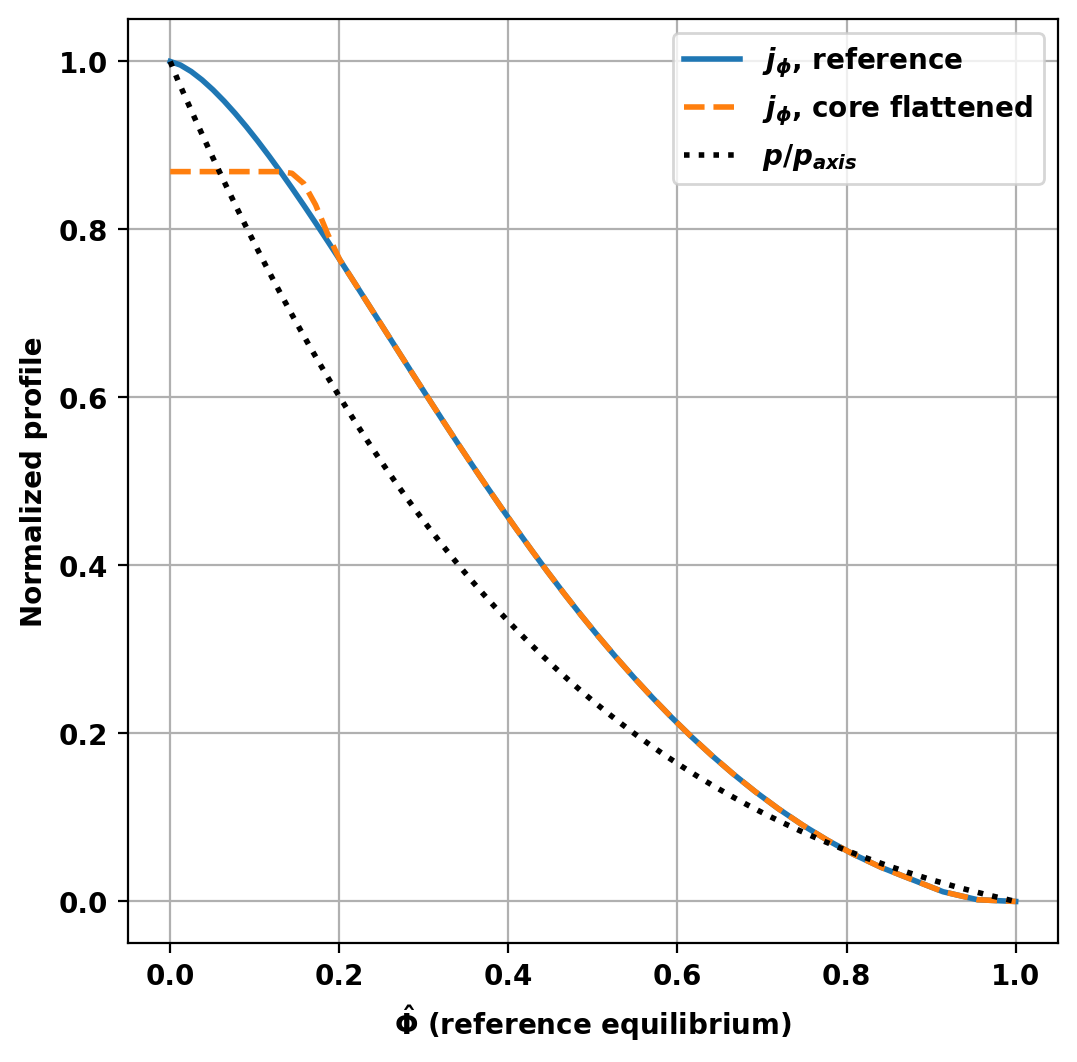

In [6]:
psi_q, q, _, _, _, _ = mygs.get_q(npsi=400, psi_pad=1.E-3)
phi_q = np.r_[0.0, np.cumsum(0.5*(q[1:]+q[:-1])*np.diff(psi_q))]
phi_q /= phi_q[-1]
phi_nodes = np.interp(psi_nodes, psi_q, phi_q)
phi_nodes[0], phi_nodes[-1] = 0.0, 1.0
phi_eqdsk = np.interp(psi_eqdsk, psi_q, phi_q)
pp_phi = edge_ramp*np.interp(phi_nodes, phi_eqdsk, np.gradient(eqdsk['pres'], phi_eqdsk))

def psi_profiles(jphi):
    return ({'type': 'jphi-linterp', 'x': psi_nodes, 'y': jphi},
            {'type': 'linterp', 'x': psi_nodes, 'y': pp_psi})

def phi_profiles(jphi):
    return ({'type': 'jphi-linterp', 'x': phi_nodes, 'y': jphi, 'coord': 'phi_n_relabel'},
            {'type': 'linterp', 'x': phi_nodes, 'y': pp_phi, 'coord': 'phi_n'})

fig, ax = plt.subplots(1,1)
ax.plot(phi_nodes, jphi_ref, label=r'$j_\phi$, reference')
ax.plot(phi_nodes, jphi_new, '--', label=r'$j_\phi$, core flattened')
ax.plot(phi_eqdsk, eqdsk['pres']/eqdsk['pres'][0], 'k:', label=r'$p/p_{axis}$')
ax.set_xlabel(r'$\hat{\Phi}$ (reference equilibrium)')
ax.set_ylabel('Normalized profile')
ax.grid(True)
_ = ax.legend()

## Re-solve with a new current profile
We now re-solve with the same pressure profile in three ways:
 - Control: the reference current profile, both profiles on $\hat{\Phi}$. This should reproduce the reference; the residual shows the numerical floor (interpolation and the $\hat{\Phi}$ map).
 - The flattened current profile, both profiles on $\hat{\psi}$.
 - The flattened current profile, both profiles on $\hat{\Phi}$.

In [7]:
cases = {
    r'Control: reference $j_\phi$, on $\hat{\Phi}$': solve(*phi_profiles(jphi_ref)),
    r'Flattened $j_\phi$, on $\hat{\psi}$': solve(*psi_profiles(jphi_new)),
    r'Flattened $j_\phi$, on $\hat{\Phi}$': solve(*phi_profiles(jphi_new)),
}

 Inverting real matrix
   Time =    9.8390000000000002E-006
 Inverting real matrix
   Time =    2.3140000000000002E-006


Starting non-linear GS solver
     1  1.0000E+00 -9.6040E-06  3.1425E-03  1.7832E+00 -3.9970E-02 -2.0404E+02


     2  1.0000E+00 -9.2838E-06  7.6879E-04  1.7787E+00 -3.9870E-02 -1.8611E+02
     3  1.0000E+00 -9.2874E-06  2.5967E-04  1.7763E+00 -3.9676E-02 -1.7351E+02


     4  1.0000E+00 -9.3017E-06  1.2548E-04  1.7752E+00 -3.9505E-02 -1.6418E+02
     5  1.0000E+00 -9.3072E-06  6.7643E-05  1.7746E+00 -3.9378E-02 -1.5823E+02


     6  1.0000E+00 -9.3088E-06  3.6921E-05  1.7743E+00 -3.9290E-02 -1.5468E+02
     7  1.0000E+00 -9.3092E-06  2.0155E-05  1.7742E+00 -3.9231E-02 -1.5260E+02


...

     4  1.0000E+00 -9.5694E-06  1.1394E-04  1.7746E+00 -3.9541E-02 -1.8447E+02
     5  1.0000E+00 -9.5755E-06  6.2302E-05  1.7741E+00 -3.9426E-02 -1.7894E+02


     6  1.0000E+00 -9.5772E-06  3.4352E-05  1.7739E+00 -3.9349E-02 -1.7561E+02
     7  1.0000E+00 -9.5775E-06  1.8850E-05  1.7738E+00 -3.9300E-02 -1.7367E+02


     8  1.0000E+00 -9.5775E-06  1.0334E-05  1.7737E+00 -3.9269E-02 -1.7255E+02
     9  1.0000E+00 -9.5775E-06  5.6857E-06  1.7737E+00 -3.9249E-02 -1.7190E+02


    10  1.0000E+00 -9.5775E-06  3.1504E-06  1.7737E+00 -3.9237E-02 -1.7153E+02
    11  1.0000E+00 -9.5775E-06  1.7619E-06  1.7737E+00 -3.9229E-02 -1.7131E+02


    12  1.0000E+00 -9.5774E-06  9.9527E-07  1.7737E+00 -3.9225E-02 -1.7119E+02
 Timing:   2.3104312198702246     
   Source:    0.54542417544871569     
   Solve:     0.26913773757405579     
   Boundary:   6.9845060352236032E-003
   Other:      1.4888848008122295     


### Plot pressure change
For each case we plot the change in pressure relative to the reference equilibrium, normalized to the peak reference pressure, with pressure contours of the reference (solid) and of the new equilibrium (dashed). The titles give the maximum and mean (area-weighted over the plasma) of the absolute change.

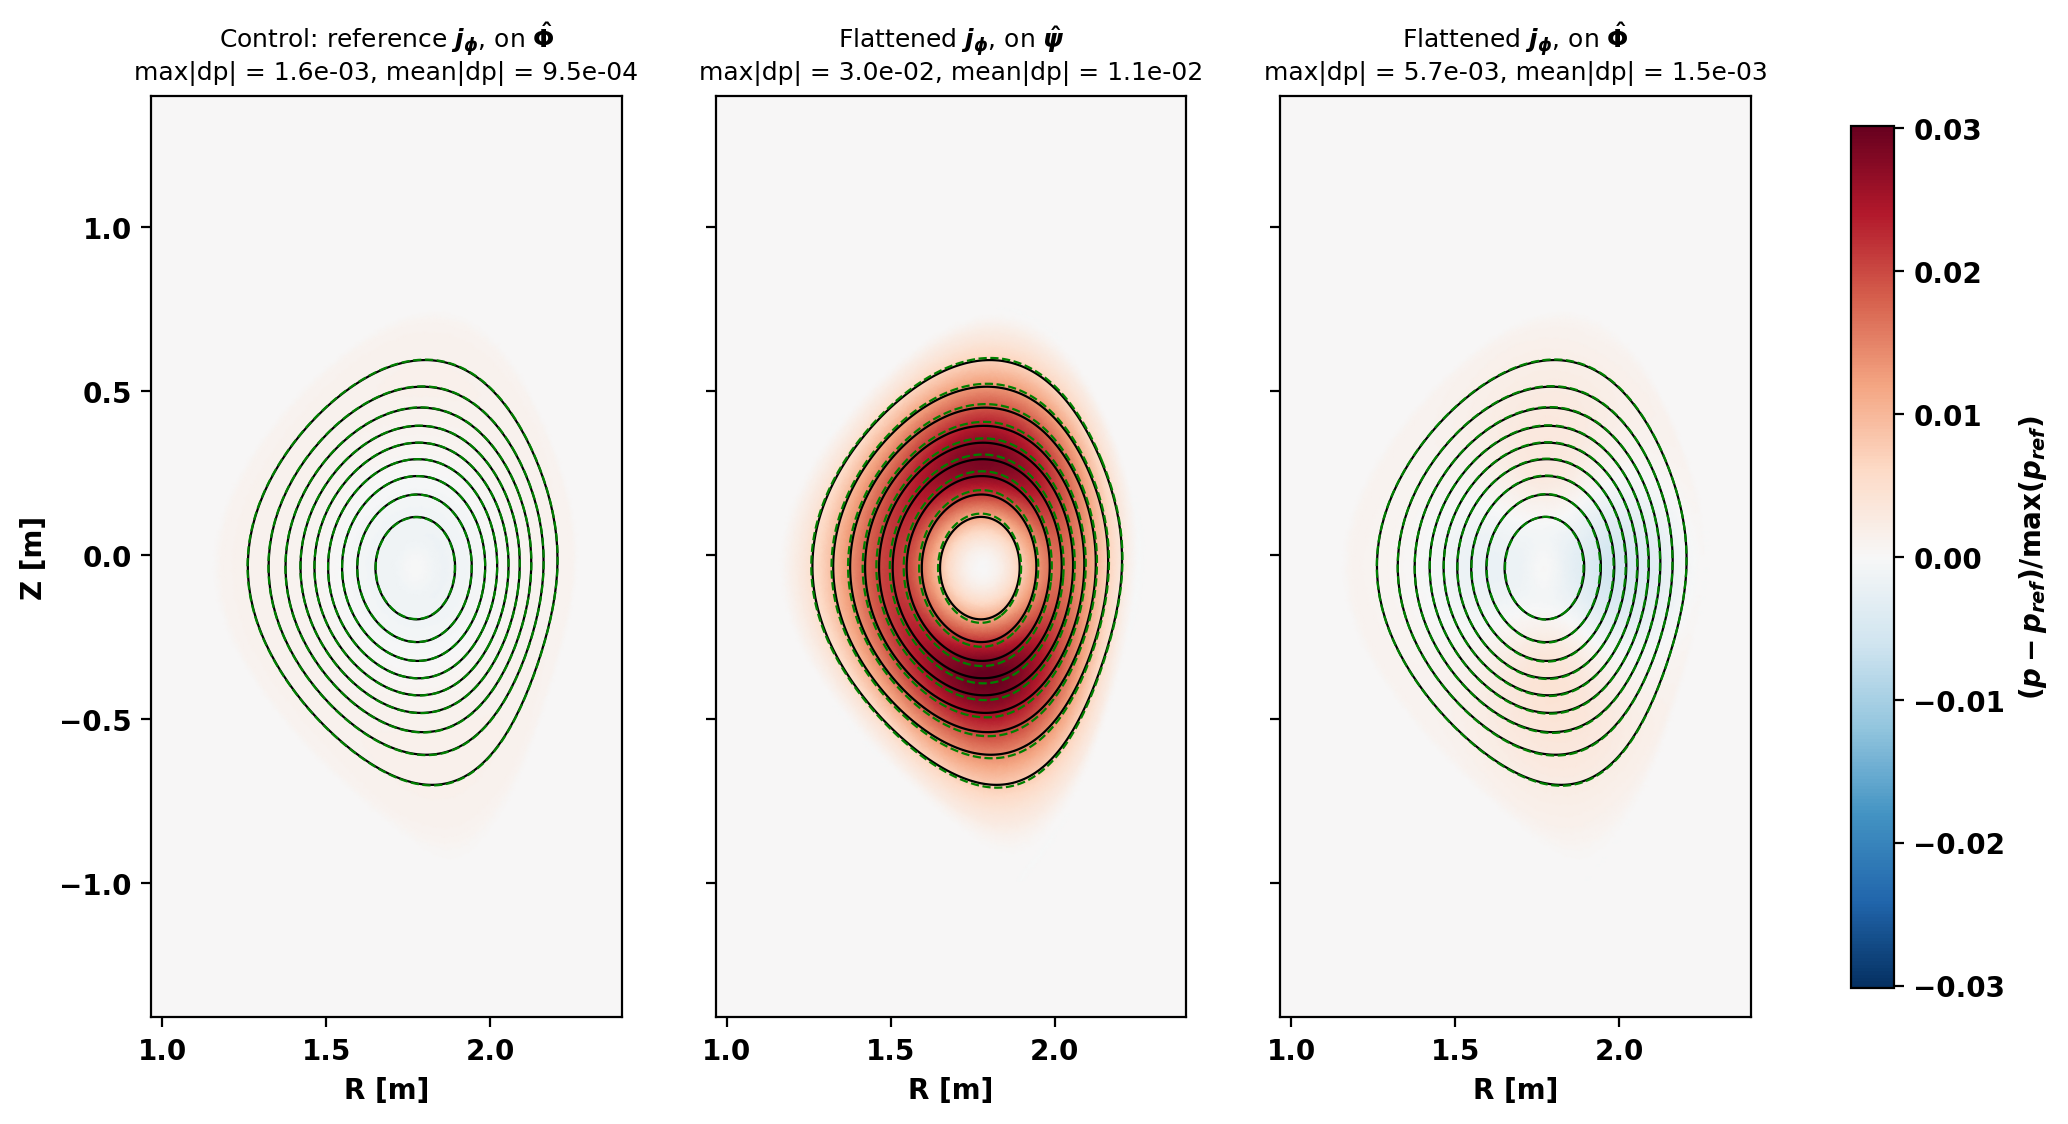

In [8]:
def plot_pressure_change(cases):
    tri = (mygs.r[:,0], mygs.r[:,1], mygs.lc)
    x_c, y_c = mygs.r[mygs.lc,0], mygs.r[mygs.lc,1]
    area = 0.5*np.abs((x_c[:,1]-x_c[:,0])*(y_c[:,2]-y_c[:,0]) - (x_c[:,2]-x_c[:,0])*(y_c[:,1]-y_c[:,0]))
    dp = {key: (p-p_ref)/p_ref.max() for key, p in cases.items()}
    vmax = max(np.abs(val).max() for val in dp.values())
    levels = np.linspace(0.1,0.9,9)*p_ref.max()
    rz_plasma = mygs.r[np.unique(mygs.lc[mygs.reg == 1]),:2]
    fig, axs = plt.subplots(1,len(cases),figsize=(4.3*len(cases),7),sharex=True,sharey=True)
    for ax, (key, p) in zip(axs, cases.items()):
        mask = np.any((p_ref[mygs.lc] > 0.0) | (p[mygs.lc] > 0.0), axis=1)
        mean_dp = np.sum(area[mask]*np.abs(dp[key][mygs.lc[mask]]).mean(axis=1))/area[mask].sum()
        clf = ax.tripcolor(*tri, dp[key], shading='gouraud', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        ax.tricontour(*tri, p_ref, levels=levels, colors='k', linewidths=0.8)
        ax.tricontour(*tri, p, levels=levels, colors='g', linewidths=0.8, linestyles='--')
        ax.set_title('{0}\nmax|dp| = {1:.1e}, mean|dp| = {2:.1e}'.format(key, np.abs(dp[key]).max(), mean_dp), fontsize=9)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel('R [m]')
    axs[0].set_xlim(rz_plasma[:,0].min()-0.05, rz_plasma[:,0].max()+0.05)
    axs[0].set_ylim(rz_plasma[:,1].min()-0.05, rz_plasma[:,1].max()+0.05)
    axs[0].set_ylabel('Z [m]')
    fig.colorbar(clf, ax=axs, shrink=0.8, label=r'$(p - p_{ref})/\max(p_{ref})$')

plot_pressure_change(cases)

The control reproduces the reference to a fraction of a percent. With the flattened current profile, the pressure held on $\hat{\psi}$ moves by up to 3% of its peak value (1% on average over the plasma), while the pressure held on $\hat{\Phi}$ moves 5 to 7 times less.

## Re-solve the reference with bootstrap current
In practice the new current profile often comes from a model, such as the bootstrap current computed from kinetic profiles. Here we reload the reference equilibrium using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.replace_eq "replace_eq()" and re-solve it with \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.solve_bootstrap "solve_bootstrap()", using the flattened profile above as the inductive current.

The kinetic profiles reproduce the reference pressure: we take an H-mode-like density profile, and the temperature from $p = e(n_e T_e + n_i T_i)$ with $T_i = T_e$ and $n_i = n_e$. With `coord='phi_n'` all profile grids passed to `solve_bootstrap()` are in $\hat{\Phi}$.

In [9]:
ne = Hmode_profiles(edge=0.2, ped=0.35, core=0.45, rgrid=len(psi_nodes), expin=1.6, expout=1.6, widthp=0.06)*1.E20
Te = p_ref_nodes/(2.0*1.602176634E-19*ne)  # [eV]

boot_cases = {}
boot_results = {}
for coord, x, label in (('psi_n', psi_nodes, r'Kinetic profiles on $\hat{\psi}$'),
                        ('phi_n', phi_nodes, r'Kinetic profiles on $\hat{\Phi}$')):
    mygs.replace_eq(source_file='DIIID_torflux_ref.h5')
    boot_results[label] = mygs.solve_bootstrap(
        ffp_prof={'x': x, 'y': jphi_new},
        te_prof={'x': x, 'y': Te/1.E3},
        ne_prof={'x': x, 'y': ne},
        ti_prof={'x': x, 'y': Te/1.E3},
        ni_prof={'x': x, 'y': ne},
        Zeff=2.0,
        Ip_target=eqdsk['ip'],
        coord=coord
    )
    boot_cases[label] = mygs.get_field_eval('P').eval(mygs.r[:,:2])[:,0]

Starting non-linear GS solver


     1  1.0000E+00  9.5384E-02  2.5642E-04  1.7736E+00 -3.9126E-02 -1.5688E+02


     2  1.0000E+00  9.7041E-02  2.2978E-04  1.7733E+00 -3.9152E-02 -1.8011E+02


     3  1.0000E+00  9.7820E-02  1.5628E-04  1.7733E+00 -3.9189E-02 -1.9335E+02


     4  1.0000E+00  9.8185E-02  9.7667E-05  1.7734E+00 -3.9226E-02 -2.0162E+02


...

     4  1.0000E+00  1.6448E-01  2.9828E-05  1.7736E+00 -3.9200E-02 -1.8263E+02


     5  1.0000E+00  1.6450E-01  1.3969E-05  1.7736E+00 -3.9217E-02 -1.8367E+02


  Freezing bootstrap solution.
     6  1.0000E+00  1.6450E-01  6.6839E-06  1.7736E+00 -3.9228E-02 -1.8421E+02


     7  1.0000E+00  1.6451E-01  3.2676E-06  1.7736E+00 -3.9235E-02 -1.8450E+02
     8  1.0000E+00  1.6451E-01  1.6374E-06  1.7736E+00 -3.9240E-02 -1.8466E+02


     9  1.0000E+00  1.6451E-01  8.4290E-07  1.7736E+00 -3.9243E-02 -1.8475E+02
 Timing:   3.1062143959570676     
   Source:    0.41690378380008042     
   Solve:     0.20329170534387231     
   Boundary:   5.4774417076259851E-003
   Other:      2.4805414651054889     


### Plot current profiles and pressure change
The results of `solve_bootstrap()` are given at the $\hat{\psi}$ of each profile node (`'psi_n'`), for either coordinate.

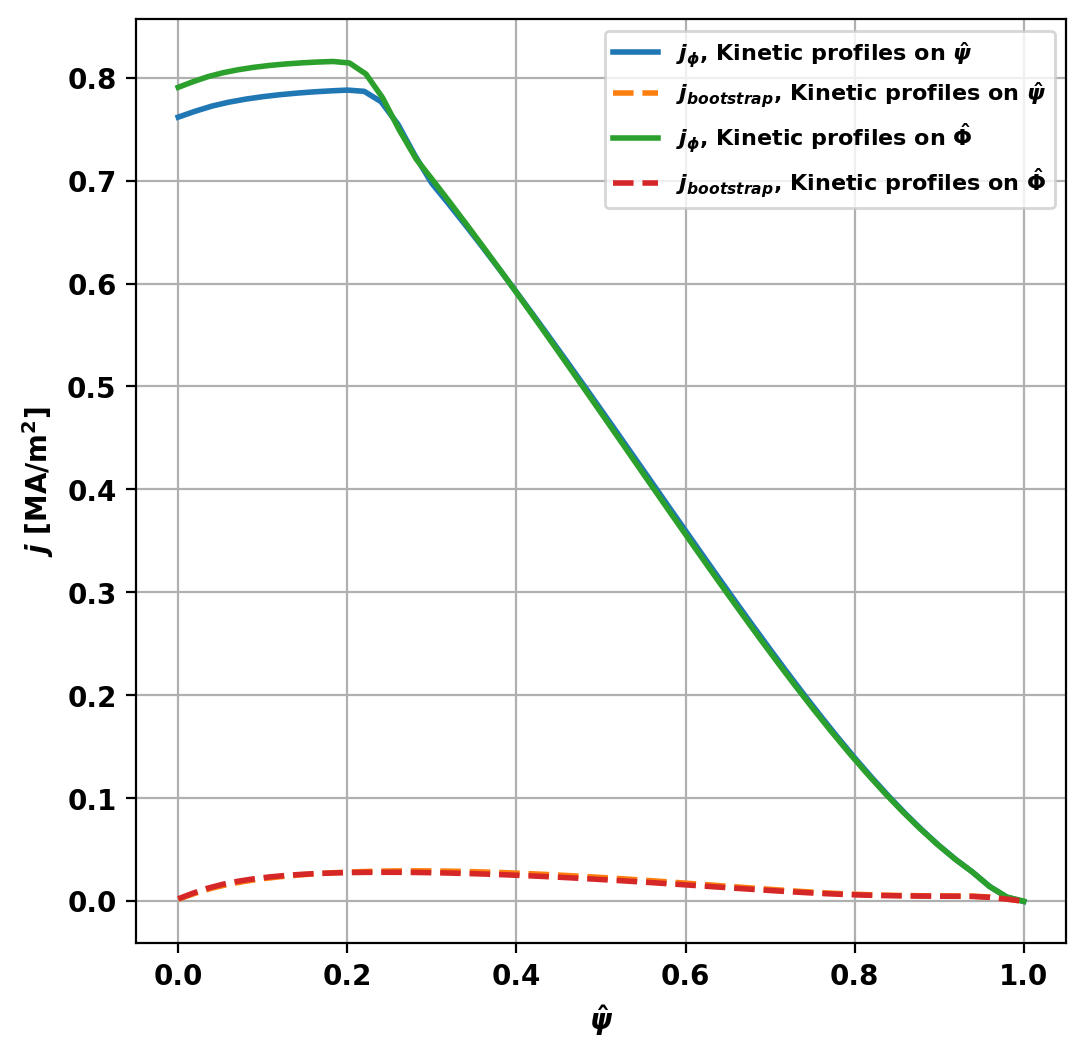

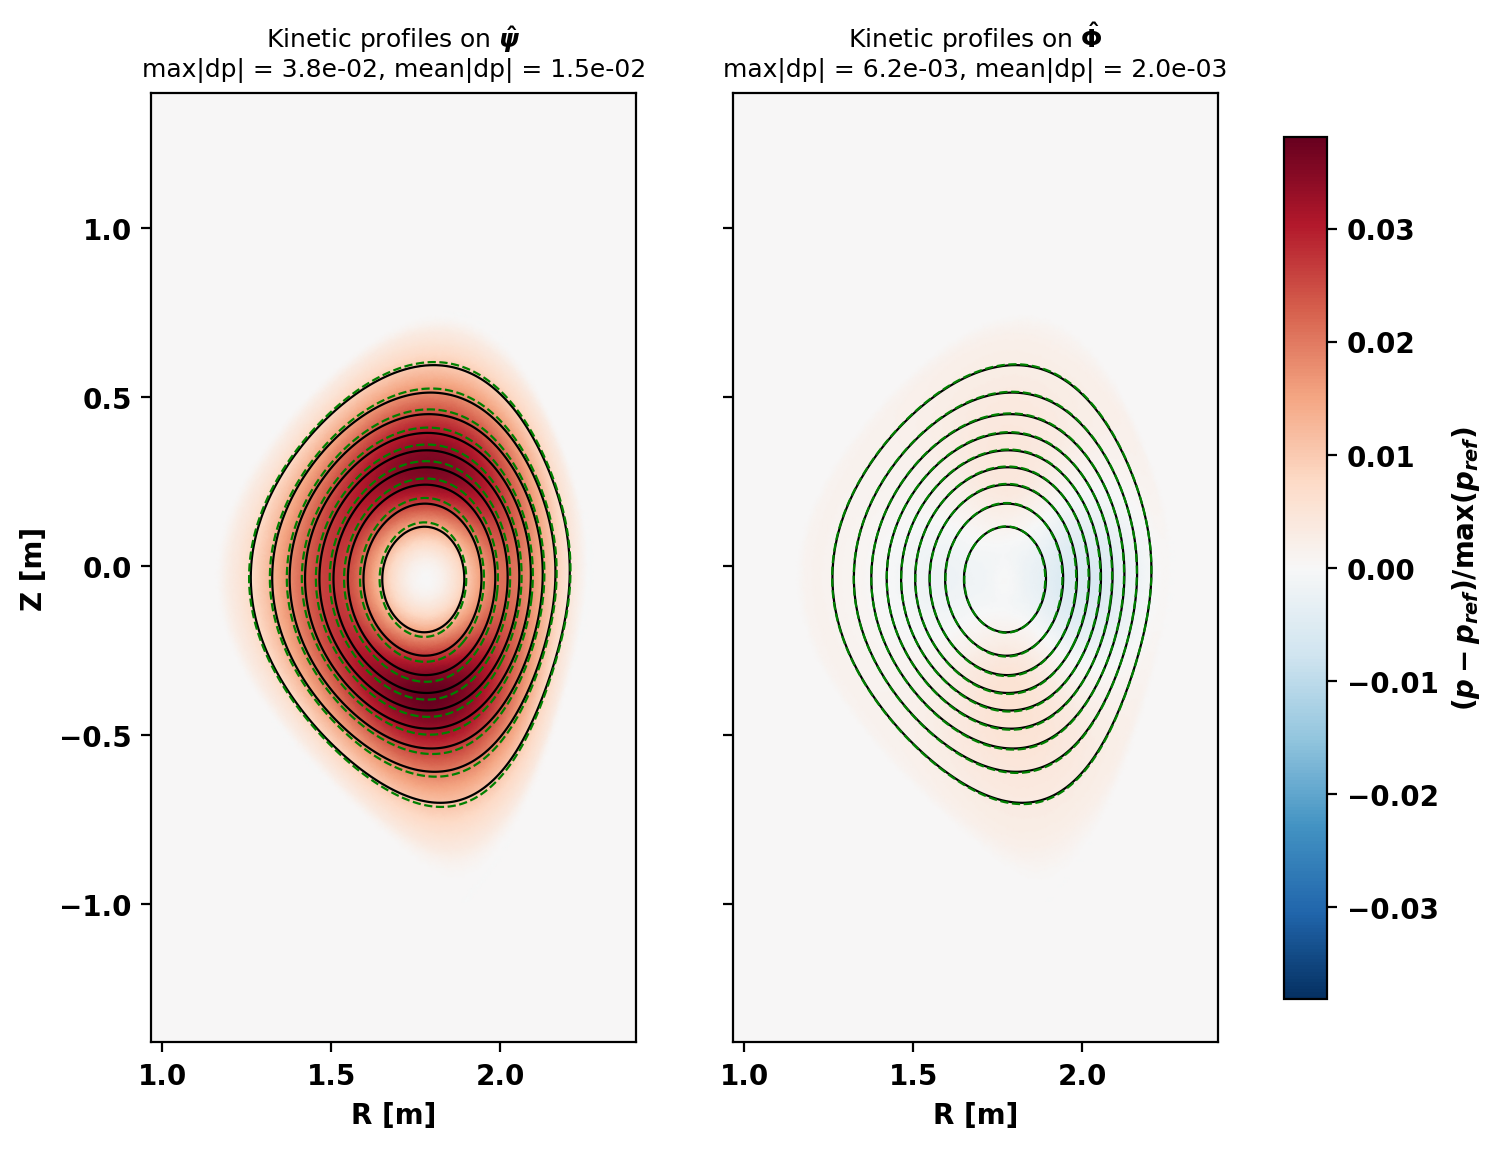

In [10]:
fig, ax = plt.subplots(1,1)
for label, results in boot_results.items():
    ax.plot(results['psi_n'], results['jphi_total']/1.E6, label=r'$j_\phi$, '+label)
    ax.plot(results['psi_n'], results['jphi_bs_final']/1.E6, '--', label=r'$j_{bootstrap}$, '+label)
ax.set_xlabel(r'$\hat{\psi}$')
ax.set_ylabel(r'$j$ [MA/m$^2$]')
ax.grid(True)
_ = ax.legend(fontsize=8)

plot_pressure_change(boot_cases)

The bootstrap current of this low-pressure equilibrium is small, so the change in pressure comes mostly from the flattened inductive current, as in the first part. Again the kinetic profiles held on $\hat{\Phi}$ keep the pressure 6 to 8 times closer to the reference than those held on $\hat{\psi}$.